# Feature Preparation, ViT-L/14

the same steps as `feature_prep.ipynb` on the 768 ViT-L/14 numbers: pca to 32 fitted on train, angles in 0 to pi, per-component auc, and how much signal the inputs carry on val. the inner fitness split is not drawn again, it is loaded from the phase 1 prep, so both encoders use the exact same frames for search and fitness.

In [1]:
import os
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

seed = 0
np.random.seed(seed)

data_dir = "/kaggle/input/datasets/malakkhaled202300369/nic-clip768-l14-dataset/features_l14"
old_prep_dir = "/kaggle/input/datasets/malakkhaled202300369/nic-feature-dataset/prep"
out_dir = "/kaggle/working/prep_l14"
os.makedirs(out_dir, exist_ok=True)

n_components = 32
low, high = 0.5, 99.5   # angle range from train percentiles, so a few extreme frames don't squeeze the rest
names = ["ffpp_train", "ffpp_val", "ffpp_test", "celebdf_test"]

In [2]:
clip, meta = {}, {}
for name in names:
    clip[name] = np.load(f"{data_dir}/{name}_clip.npy")
    meta[name] = pd.read_csv(f"{data_dir}/{name}_rows.csv")
    print(name, clip[name].shape)

# same rows in the same order as phase 1
for name in ["ffpp_train", "ffpp_val"]:
    old = pd.read_csv(f"{old_prep_dir}/{name}_rows.csv")
    assert (old["path"].to_numpy() == meta[name]["path"].to_numpy()).all(), name

is_inner = np.load(f"{old_prep_dir}/ffpp_train_is_inner.npy").astype(bool)
shutil.copy(f"{old_prep_dir}/ffpp_inner_fitness.json", f"{out_dir}/ffpp_inner_fitness.json")
print("search-train frames:", (~is_inner).sum(), "(expected 39164)")
print("inner fitness frames:", is_inner.sum(), "(expected 6912)")

ffpp_train (46076, 768)
ffpp_val (22396, 768)
ffpp_test (22400, 768)
celebdf_test (16572, 768)
search-train frames: 39164 (expected 39164)
inner fitness frames: 6912 (expected 6912)


## pca and angles

each clip vector is scaled to length 1, pca and the angle range are fitted on train only and applied to the rest, as in phase 1.

In [3]:
xn = {name: clip[name] / np.linalg.norm(clip[name], axis=1, keepdims=True) for name in names}

pca = PCA(n_components=n_components, svd_solver="full")
pca.fit(xn["ffpp_train"])
z = {name: pca.transform(xn[name]) for name in names}

lo = np.percentile(z["ffpp_train"], low, axis=0)
hi = np.percentile(z["ffpp_train"], high, axis=0)
angles = {name: np.clip((z[name] - lo) / (hi - lo), 0.0, 1.0) * np.pi for name in names}

for name in names:
    np.save(f"{out_dir}/{name}_pca32.npy", z[name].astype(np.float32))
    np.save(f"{out_dir}/{name}_angles32.npy", angles[name].astype(np.float32))
    meta[name].to_csv(f"{out_dir}/{name}_rows.csv", index=False)
np.save(f"{out_dir}/ffpp_train_is_inner.npy", is_inner)
np.savez(f"{out_dir}/pca32_params.npz", components=pca.components_, mean=pca.mean_,
         explained_variance_ratio=pca.explained_variance_ratio_, angle_lo=lo, angle_hi=hi)

cum = np.cumsum(pca.explained_variance_ratio_)
for k in [4, 8, 12, 32]:
    print(f"variance kept by the first {k:2d} components: {100 * cum[k - 1]:.1f}%")

variance kept by the first  4 components: 25.5%
variance kept by the first  8 components: 35.4%
variance kept by the first 12 components: 41.6%
variance kept by the first 32 components: 60.3%


## per-component auc

auc of each component on its own, on search-train and val. a component can be high for fakes or for reals, so the strength is max(auc, 1 - auc).

best 8 on search-train: [1, 2, 5, 7, 8, 9, 11, 30]
of them in the first 8: 4


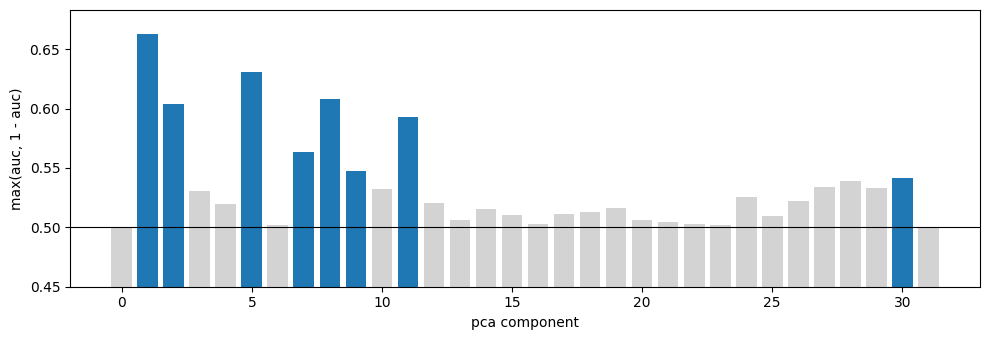

In [4]:
train = meta["ffpp_train"]
y_train = train["label"].to_numpy()
y_val = meta["ffpp_val"]["label"].to_numpy()
st = ~is_inner

comp = []
for j in range(n_components):
    auc_st = roc_auc_score(y_train[st], z["ffpp_train"][st, j])
    auc_val = roc_auc_score(y_val, z["ffpp_val"][:, j])
    comp.append({"component": j, "variance_pct": 100 * pca.explained_variance_ratio_[j],
                 "auc_search_train": auc_st, "strength_search_train": max(auc_st, 1 - auc_st),
                 "auc_val": auc_val, "strength_val": max(auc_val, 1 - auc_val)})
comp = pd.DataFrame(comp)
comp.to_csv(f"{out_dir}/per_component_auc.csv", index=False)

best8 = comp.sort_values("strength_search_train", ascending=False)["component"].head(8).tolist()
print("best 8 on search-train:", sorted(best8))
print("of them in the first 8:", sum(j < 8 for j in best8))

plt.figure(figsize=(10, 3.5))
plt.bar(comp["component"], comp["strength_search_train"],
        color=["tab:blue" if j in best8 else "lightgray" for j in comp["component"]])
plt.axhline(0.5, color="black", linewidth=0.8)
plt.xlabel("pca component")
plt.ylabel("max(auc, 1 - auc)")
plt.ylim(0.45, comp["strength_search_train"].max() + 0.02)
plt.tight_layout()
plt.savefig(f"{out_dir}/per_component_auc.png", dpi=150)
plt.show()

## logistic regression on val

trained on all of ff++ train, scored on val at frame and video level. one fixed setting (standardized, C = 1), the same sanity check as phase 1. phase 1 with ViT-B/16: first 8 0.636, best 8 0.713, all 32 0.757, linear probe 0.893.

In [5]:
val = meta["ffpp_val"]
val_video = val.groupby(["method", "video_id"]).ngroup().to_numpy()


def video_level(prob):
    df = pd.DataFrame({"video": val_video, "p": prob, "y": y_val})
    g = df.groupby("video").agg(p=("p", "mean"), y=("y", "first"))
    return g["p"].to_numpy(), g["y"].to_numpy()


inputs = [
    ("first 8", z["ffpp_train"][:, :8], z["ffpp_val"][:, :8]),
    ("first 12", z["ffpp_train"][:, :12], z["ffpp_val"][:, :12]),
    ("all 32", z["ffpp_train"], z["ffpp_val"]),
    ("best 8", z["ffpp_train"][:, best8], z["ffpp_val"][:, best8]),
    ("768 linear probe", xn["ffpp_train"], xn["ffpp_val"]),
]

table, probs = [], {}
for name, xt, xv in inputs:
    model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000))
    model.fit(xt, y_train)
    probs[name] = model.predict_proba(xv)[:, 1]
    pv, yv = video_level(probs[name])
    table.append({"input": name, "frame auc": round(roc_auc_score(y_val, probs[name]), 3),
                  "video auc": round(roc_auc_score(yv, pv), 3)})

table = pd.DataFrame(table)
table.to_csv(f"{out_dir}/bottleneck_check.csv", index=False)
print(table.to_string(index=False))

           input  frame auc  video auc
         first 8      0.713      0.739
        first 12      0.763      0.784
          all 32      0.787      0.810
          best 8      0.761      0.782
768 linear probe      0.871      0.899


## val auc per manipulation method

each method's fakes against all real videos, at video level.

In [6]:
video_method = val.groupby(["method", "video_id"])["method"].first().to_numpy()

per_method = []
for name in ["first 8", "768 linear probe"]:
    pv, yv = video_level(probs[name])
    for m in ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]:
        keep = (video_method == "original") | (video_method == m)
        per_method.append({"input": name, "method": m, "video auc": roc_auc_score(yv[keep], pv[keep])})

per_method = pd.DataFrame(per_method)
per_method.to_csv(f"{out_dir}/per_method_auc.csv", index=False)
print(per_method.pivot(index="method", columns="input", values="video auc").round(3).to_string())

input           768 linear probe  first 8
method                                   
Deepfakes                  0.976    0.939
Face2Face                  0.861    0.638
FaceSwap                   0.956    0.906
NeuralTextures             0.803    0.473
